![Banner](../../../../Images/Banner/03_spatial_analysis/03_07_banner_spatial_causal.png)

# Spatial Causal Discovery



This notebook learns directed relationships among county health measures. A
simulated 24-year panel on the real county map is the case with a known
direction. Geographical convergent cross mapping and NOTEARS use real 2024
County Health Rankings measures, where no ground truth exists.

The methods are spatial Granger causality, geographical convergent cross
mapping, and NOTEARS with spatial-lag nodes. The classes are `SpatialGranger`
and `GCCM` in `geolattice.spatial_analysis.spatialcausal`.



## Table of Contents

- [Overview](#overview)
- [Spatial Granger causality](#spatial-granger-causality)
- [Geographical convergent cross mapping (GCCM) on real data](#geographical-convergent-cross-mapping-gccm-on-real-data)
- [NOTEARS with spatial-lag nodes on real data](#notears-with-spatial-lag-nodes-on-real-data)
- [Summary and Conclusions](#summary-and-conclusions)
- [Resources](#resources)


## Overview

The earlier notebooks *assumed* a causal structure (treatment → outcome) and estimated its strength.
Causal discovery tries to *learn* the structure from data. It needs strong assumptions, and its output
is a set of hypotheses to be tested with designs like those in notebooks 01-07, never a conclusion.

Spatial panel Granger causality is fit to the simulated panel, where the direction is known.
Geographical convergent cross mapping (GCCM) and NOTEARS with spatial-lag nodes are applied to
**real** CHR 2024 county measures, where no ground truth exists.


**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import geolattice.spatial_analysis.spatialcausal as sc, countycausal as cc, tutorial_style as ts
from geolattice.spatial_analysis.spatialcausal._utils import as_sparse_weights
ts.use()

g = cc.build_county_frame()
w = cc.queen_weights()
xy = cc.coords_km(g)
n = len(g)

***
## Spatial Granger causality

$x$ **Granger-causes** $y$ if past $x$ improves the prediction of $y$ beyond $y$'s own past. With
county panels and neighbours:

$$y_{it}=a_i+l_t+\sum_{\ell=1}^{L}\Big[\rho_\ell\,y_{i,t-\ell}+\gamma_\ell\,(Wy)_{i,t-\ell}
+\beta_\ell\,x_{i,t-\ell}+\eta_\ell\,(Wx)_{i,t-\ell}\Big]+e_{it}.$$

$H_0^{\text{local}}:\beta=0$ (own past $x$) and $H_0^{\text{spillover}}:\eta=0$ (neighbours' past $x$)
are tested with cluster-robust Wald statistics and a Hotelling-type $F(q,G-q)$ reference.

**Two traps, both handled by `SpatialGranger`:**

1. **Nickell bias.** With unit fixed effects and lagged regressors, the within transformation
   correlates the demeaned error with the demeaned lags: the bias is of order $1/T$ (Nickell, 1981).
   In a large panel this small bias becomes "significant" and produces *spurious* Granger
   causality. The **half-panel jackknife** (Dhaene & Jochmans, 2015) removes the $O(1/T)$ term:
   $\hat\beta_{\text{HJ}}=2\hat\beta-\tfrac12(\hat\beta_{\text{first half}}+\hat\beta_{\text{second half}})$.
2. **Cross-sectional dependence.** Shocks hitting neighbouring counties in the same year make
   unit-clustered SEs too small; we cluster on spatial blocks of counties.

**Why not the CHR panel?** CHR offers six annual releases (2020-2025), many measures pool several
data years, and adjacent releases overlap. That is too few, too smooth time points for dynamic
models (the jackknife needs at least three periods per half). We therefore simulate a 24-year panel
on the **real county map**: $x$ is a spatially autocorrelated AR(1) process, and
$y_{it}=0.4y_{i,t-1}+0.5x_{i,t-1}+0.4(Wx)_{i,t-1}+a_i+e_{it}$, so $x\to y$ and *not* $y\to x$.


In [2]:
rng = np.random.default_rng(5)
Wr = as_sparse_weights(w, n, row_standardize=True)
T_, burn = 24, 20
x = np.zeros((n, T_ + burn)); y = np.zeros((n, T_ + burn)); a = rng.normal(0, 0.5, n)
for t in range(1, T_ + burn):
    shock = rng.normal(size=n)
    x[:, t] = 0.5 * x[:, t - 1] + 0.5 * (Wr @ shock) + 0.5 * shock
    y[:, t] = 0.4 * y[:, t - 1] + 0.5 * x[:, t - 1] + 0.4 * (Wr @ x[:, t - 1]) + a + rng.normal(0, 0.7, n)
x, y = x[:, burn:], y[:, burn:]
panel = sc.SpatialPanel(np.repeat(g.fips, T_), np.tile(np.arange(T_), n), y.ravel(), g.fips, xy, X=x.ravel()[:, None])

fwd = sc.SpatialGranger(lags=1, w=w).fit(panel, cause=0)
print(fwd.summary())

Spatial Granger causality (lags=1)
           coef      se         t  p_value
y_lag1   0.4045  0.0030  133.5255   0.0000
Wy_lag1  0.0140  0.0063    2.2183   0.0265
x_lag1   0.5030  0.0061   82.0812   0.0000
Wx_lag1  0.3936  0.0103   38.2752   0.0000

  H0 no local     Granger causality: F=6737.323, df=(1, 309), p=7.156e-212
  H0 no spillover Granger causality: F=1464.995, df=(1, 309), p=2.712e-119
  H0 no joint     Granger causality: F=9447.778, df=(2, 308), p=3.945e-277


In [3]:
rows = {}
for bc in (None, "jackknife"):
    for cl in ("unit", "spatial"):
        r = sc.SpatialGranger(lags=1, w=w, bias_correction=bc, cluster=cl).fit(panel, cause=panel.y, effect=x.ravel())
        # in the reverse regression the "effect" is x and the "cause" is y:
        # y_lag1 = x's own lag (truth 0.5), x_lag1 = lagged y (truth 0)
        rows[(bc or "none", cl)] = {"x's own lag (truth 0.5)": r.coef_.loc["y_lag1", "coef"],
                                     "lagged y (truth 0)": r.coef_.loc["x_lag1", "coef"],
                                     "p: y Granger-causes x": r.tests_["joint"]["p_value"]}
rev = pd.DataFrame(rows).T
rev.index.names = ["bias correction", "clustering"]
rev.round(4)

x's own lag (truth 0.5)  lagged y (truth 0)  \
bias correction clustering                                                
none            unit                         0.4322             -0.0175   
                spatial                      0.4322             -0.0175   
jackknife       unit                         0.5039             -0.0008   
                spatial                      0.5039             -0.0008   

                            p: y Granger-causes x  
bias correction clustering                         
none            unit                       0.0000  
                spatial                    0.0000  
jackknife       unit                       0.7696  
                spatial                    0.8713

In the reverse regression (does $y$ Granger-cause $x$?), Nickell bias pulls $x$'s own persistence
down from 0.5 to 0.43 and pushes the coefficient on lagged $y$ away from 0. With about 71,500
observations that small bias is "significant" ($p<0.0001$): a spurious causal finding. The
half-panel jackknife restores both coefficients and the test no longer rejects. In this simulation
the shocks' spatial correlation is mild, so clustering matters less than the bias correction.

***
## Geographical convergent cross mapping (GCCM) on real data

CCM (Sugihara et al., 2012) comes from dynamical systems. If $x$ drives $y$, then $y$'s state carries
an imprint of $x$, so $x$ can be **cross-mapped** (predicted) from a reconstruction of $y$'s state space.
GCCM (Gao et al., 2023) replaces time delays with spatial lags:

$$M_y(i)=\Big(y_i,\ \bar y^{(1)}_i,\ \dots,\ \bar y^{(E-1)}_i\Big),\qquad \bar y^{(k)}_i=\text{mean of }y\text{ over the }k\text{-th ring of neighbours}.$$

To predict $x_i$, find the $E+1$ nearest neighbours of $M_y(i)$ among a library of $L$ counties
and average their $x$ with weights $w_k\propto\exp(-d_k/d_1)$ (simplex projection). The cross-map skill is
$\rho(L)=\operatorname{corr}(\hat x,x)$. **Evidence for $x\to y$ is skill that rises and converges as
$L$ grows**, not merely high skill.

**A spatial exclusion zone is essential.** Neighbouring counties share neighbour rings, so their
embeddings are similar by construction. Using them as "nearest neighbours" lets ordinary spatial
autocorrelation masquerade as cross-map skill. `geolattice.spatial_analysis.spatialcausal` excludes every county within
$2(E-1)$ rings of the target, a spatial analogue of the Theiler window. (In package tests, two
independent smooth fields showed skill ≈ 0.5 without it.)


,skill,p_skill,convergence_gain,p_convergence
inactivity_pct | x_causes_y,0.822,0.0,0.024,0.000
inactivity_pct | y_causes_x,0.823,0.0,0.036,0.000
obesity_pct | x_causes_y,0.608,0.0,0.031,0.001
obesity_pct | y_causes_x,0.631,0.0,0.020,0.074
broadband_pct | x_causes_y,0.505,0.0,0.014,0.079
broadband_pct | y_causes_x,0.590,0.0,-0.001,0.556


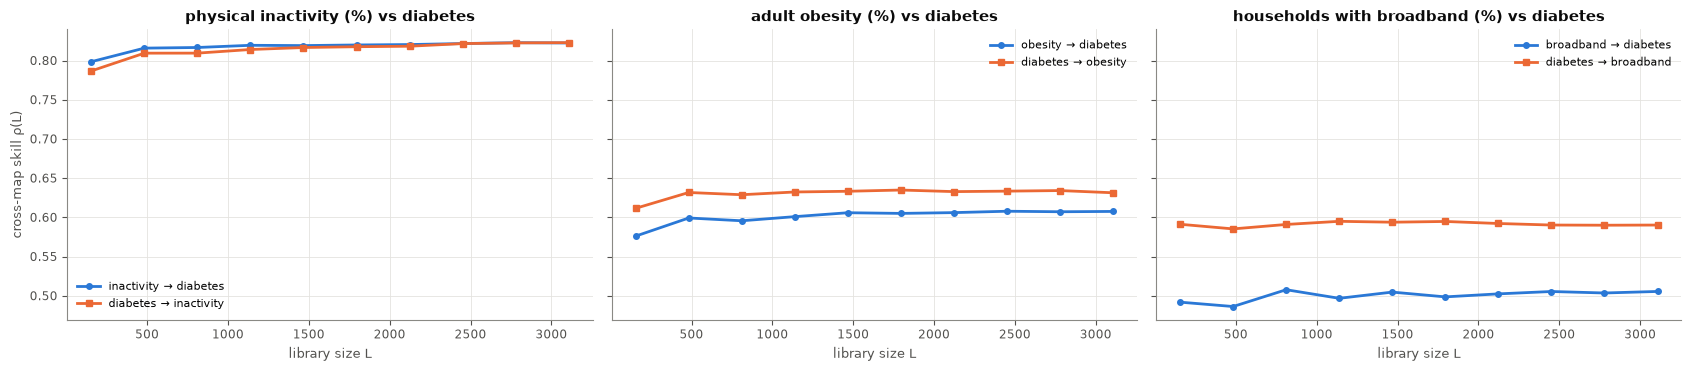

In [4]:
pairs = [("inactivity_pct", "diabetes_pct"), ("obesity_pct", "diabetes_pct"), ("broadband_pct", "diabetes_pct")]
fits = {}
for xa, ya in pairs:
    fits[(xa, ya)] = sc.GCCM(E=3, n_rep=8, random_state=0).fit(g[xa].to_numpy(), g[ya].to_numpy(), w=w)
leak = sc.GCCM(E=3, n_rep=8, exclusion=0, random_state=0).fit(g["inactivity_pct"].to_numpy(), g["diabetes_pct"].to_numpy(), w=w)

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for a, (xa, ya) in zip(ax, pairs):
    sk = fits[(xa, ya)].skill_
    a.plot(sk.index, sk["x_causes_y"], "o-", color=ts.BLUE, ms=4, label=f"{xa.replace('_pct','')} → diabetes")
    a.plot(sk.index, sk["y_causes_x"], "s-", color=ts.ORANGE, ms=4, label=f"diabetes → {xa.replace('_pct','')}")
    a.set_xlabel("library size L"); a.set_title(f"{cc.LABELS[xa]} vs diabetes")
    a.legend(fontsize=8)
ax[0].set_ylabel("cross-map skill ρ(L)")
plt.tight_layout()
tests = pd.DataFrame({f"{xa} | {k}": v for (xa, ya), f in fits.items() for k, v in f.tests_.items()}).T
tests.round(3)

In [5]:
print("inactivity vs diabetes, no exclusion zone:",
      {k: round(v["skill"], 3) for k, v in leak.tests_.items()})
print("inactivity vs diabetes, exclusion zone:   ",
      {k: round(v["skill"], 3) for k, v in fits[("inactivity_pct", "diabetes_pct")].tests_.items()})

inactivity vs diabetes, no exclusion zone: {'x_causes_y': 0.841, 'y_causes_x': 0.84}
inactivity vs diabetes, exclusion zone:    {'x_causes_y': 0.822, 'y_causes_x': 0.823}


Reading these results:

* **Skill is high for every pair** (0.5-0.8), including broadband access, which nobody would argue
  causes diabetes. High skill alone reflects shared socioeconomic structure, not causation.
* **Convergence** is the CCM criterion. Inactivity and diabetes converge in *both* directions, which
  CCM cannot separate from a **common driver** (income, rurality, regional culture, or county
  estimates modelled from the same surveys). Obesity → diabetes converges and the reverse is
  borderline (p ≈ 0.07). Broadband shows no clear convergence in either direction.
* On these real data the exclusion zone lowers skill only slightly (0.84 → 0.82), so the patterns
  are not mainly neighbour leakage; on smooth simulated fields it removed most of the skill.

GCCM was designed for coupled nonlinear dynamics. Cross-sections of socially patterned county
statistics violate its assumptions, so treat these patterns as descriptive.

***
## NOTEARS with spatial-lag nodes on real data

A linear structural equation model writes the variables as $\mathbf X=\mathbf X\mathbf W+\mathbf E$, where
$W_{jk}\ne0$ means $x_j\to x_k$. Learning $W$ is a search over directed *acyclic* graphs, which is
combinatorial. NOTEARS (Zheng et al., 2018) replaces it with a smooth constraint:

$$\min_W\ \frac{1}{2n}\lVert\mathbf X-\mathbf X W\rVert_F^2+\lambda\lVert W\rVert_1
\quad\text{s.t.}\quad h(W)=\operatorname{tr}\!\big(e^{W\circ W}\big)-d=0,$$

where $h(W)=0$ exactly when the graph has no cycles (the trace counts weighted closed walks). It is
solved by an augmented Lagrangian with L-BFGS, then small weights are thresholded.

**Spatial version.** We add nodes $(Wx)_j$, the neighbours' average of each variable, and forbid any
edge *into* them. Learned edges are then either **local** ($x_j\to x_k$) or **spillover**
($Wx_j\to x_k$: the neighbours' level of $x_j$ affects a county's $x_k$).

**Identifiability and scale.** Linear-Gaussian structure is only identified up to an equivalence
class, and NOTEARS partly exploits differences in marginal variance ("varsortability", Reisach et
al., 2021). Results on raw and standardised data can differ, so we standardise (comparable penalties)
and check **stability** with a spatial block bootstrap.


In [6]:
V = ["inactivity_pct", "obesity_pct", "diabetes_pct", "smoking_pct", "food_env", "log_income", "child_poverty_pct"]
short = ["inactivity", "obesity", "diabetes", "smoking", "food_env", "log_income", "child_pov"]
nt = sc.SpatialNOTEARS(lambda1=0.05, w_threshold=0.3, standardize=True).fit(g[V].to_numpy(), w=w, names=short)
print(nt.summary())

Spatial NOTEARS edges
      source     target  weight      type
W.inactivity inactivity   0.602 spillover
  inactivity   diabetes   0.549     local
  inactivity    smoking   0.449     local
     obesity inactivity   0.406     local
   W.obesity    obesity   0.883 spillover
  W.diabetes   diabetes   0.488 spillover
    diabetes  child_pov   0.371     local
   W.smoking    smoking   0.584 spillover
     smoking log_income  -0.314     local
  W.food_env   food_env   0.449 spillover
W.log_income log_income   0.477 spillover
  log_income  child_pov  -0.468     local


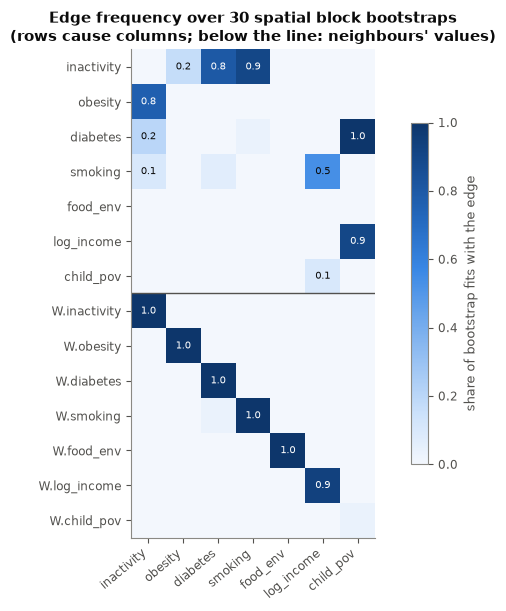

In [7]:
# spatial block bootstrap: lag nodes are computed on the full map, then whole blocks of counties are resampled
Z = g[V].to_numpy(); Z = (Z - Z.mean(0)) / Z.std(0)
L = np.asarray(Wr @ Z)
data = np.hstack([Z, L])
d = len(V)
mask = np.ones((2 * d, 2 * d), bool); mask[:, d:] = False
blocks = sc.SpatialBlockKFold(n_splits=2, n_blocks=150, random_state=0).make_blocks(xy)
members = [np.flatnonzero(blocks == b) for b in np.unique(blocks)]
B = 30
freq = np.zeros((2 * d, d))
rngb = np.random.default_rng(1)
for _ in range(B):
    idx = np.concatenate([members[i] for i in rngb.integers(0, len(members), len(members))])
    Wb = sc.notears_linear(data[idx], lambda1=0.05, w_threshold=0.3, mask=mask)
    freq += (Wb[:, :d] != 0)
freq /= B
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(freq, cmap=ts.SEQ, vmin=0, vmax=1)
ax.set_xticks(range(d), short, rotation=40, ha="right")
ax.set_yticks(range(2 * d), short + [f"W.{s}" for s in short])
ax.axhline(d - 0.5, color=ts.INK2, lw=1)
for i in range(2 * d):
    for j in range(d):
        if freq[i, j] >= 0.1:
            ax.text(j, i, f"{freq[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if freq[i, j] > 0.6 else ts.INK)
ax.grid(False)
ax.set_title("Edge frequency over 30 spatial block bootstraps\n(rows cause columns; below the line: neighbours' values)")
plt.colorbar(im, ax=ax, shrink=0.7, label="share of bootstrap fits with the edge")
plt.tight_layout()

How to read the graph:

* The strongest and most stable edges are **spillover self-edges** ($W.x\to x$): every measure
  resembles its neighbours' values. That is spatial autocorrelation, which this model can only
  represent as "neighbours cause".
* Among local edges, inactivity → diabetes (80% of fits) agrees with clinical knowledge, and so does
  log income → child poverty (90%).
* **Stability is not correctness.** Diabetes → child poverty appears in *all* 30 fits, a perfectly
  stable edge whose direction is implausible. The bootstrap measures robustness to *sampling*; it
  says nothing about whether NOTEARS oriented the edge correctly. In linear models with roughly
  Gaussian errors, orientation rests largely on variance patterns (varsortability), not on causal
  information.
* Edges present in fewer than about 70% of fits (smoking → log income, 60%) should not be interpreted.

***
## Summary and Conclusions

1. Discovery methods generate hypotheses. Their assumptions (no hidden common causes, correct
   functional form, acyclicity, deterministic coupling for CCM) are rarely met by county
   statistics.
2. Spatial data create spurious "discoveries" unless handled: Nickell bias and cross-sectional
   dependence in Granger tests, spatial autocorrelation in cross mapping, neighbour similarity
   in structure learning.
3. Report stability (bootstrap edge frequencies, convergence in both directions), not a single graph.
4. Take a stable discovered edge, such as inactivity → diabetes, back to a design: a quasi-experiment
   or trial in which the direction is identified by the intervention, not by the data's correlations.


***
## Resources

### Papers

| Reference | Notes |
|-----------|-------|
| Nickell (1981) | $O(1/T)$ bias from unit fixed effects and lagged regressors |
| Dhaene & Jochmans (2015) | Half-panel jackknife |
| Sugihara et al. (2012) | Convergent cross mapping |
| Gao et al. (2023) | Geographical CCM: spatial lags in place of time delays |
| Zheng et al. (2018) | NOTEARS |
| Reisach et al. (2021) | Varsortability: linear NOTEARS can orient edges from marginal variances |

### In this library

| Object | Role |
|--------|------|
| `SpatialGranger` | Local and spillover Granger tests, jackknife, spatial-block clustering |
| `GCCM` | Cross-map skill $\rho(L)$ with a spatial exclusion zone |
| Spatial NOTEARS | Lag nodes $(Wx)_j$ that cannot be children, plus a block bootstrap |
